# QORION — Scenario 1: Normal (Baseline) Network

**Purpose:** This notebook establishes the honest-network baseline for the QORION study.
No adversary is present. It measures how end-to-end entanglement fidelity, success rate,
and timing cost scale with (a) physical distance between Alice and Bob, and (b) the number
of intermediate quantum repeaters used to bridge that distance.

**Simulator:** SeQUeNCe 0.6.4 (physical-layer entanglement generation via Bell State
Measurement, using SeQUeNCe's `EntanglementGenerationA` and `EntanglementSwappingA`).

**Downstream use:** Results are exported to `normal_results.json` using a schema shared
across all three QORION scenario notebooks (Normal / Vulnerable / Proposed), so the
Final Analysis notebook can directly compare them without re-simulation.

In [1]:
!pip install sequence==0.6.4

## Setup

The classes below wrap SeQUeNCe's physical entanglement-generation and entanglement-swapping
primitives. Each class corresponds to a specific role in a quantum repeater network:

- `EntangleGenNode` — an endpoint (Alice, Bob, or a repeater's half) capable of generating
  one entangled link with a neighboring node via a Bell State Measurement (BSM) station.
- `SwapNodeA` — a genuine quantum **repeater**: holds two entangled memories (one linked to
  each neighbor) and performs an honest entanglement swap, fusing the two links into one
  end-to-end entangled pair.
- `SwapNodeB` — a chain **endpoint** adjacent to a repeater (holds a single memory, receives
  the result of the repeater's swap).

In [2]:
import time
import statistics

from sequence.kernel.timeline import Timeline
from sequence.topology.node import Node, BSMNode
from sequence.components.memory import Memory
from sequence.components.optical_channel import QuantumChannel, ClassicalChannel
from sequence.entanglement_management.generation import EntanglementGenerationA
from sequence.entanglement_management.swapping import EntanglementSwappingA


class SimpleManager:
    """Resource manager for a single-link entanglement-generation node.
    Required by SeQUeNCe's protocol internals (update() is called on every
    state change, even though this baseline doesn't act on RAW vs ENTANGLED
    states beyond bookkeeping)."""
    def __init__(self, own, memo_name):
        self.own = own
        self.memo_name = memo_name
        self.raw_counter = 0
        self.ent_counter = 0

    def update(self, protocol, memory, state):
        if state == 'RAW':
            self.raw_counter += 1
            memory.reset()
        else:
            self.ent_counter += 1

    def create_protocol(self, middle, other):
        self.own.protocols = [
            EntanglementGenerationA(
                self.own, f'{self.own.name}.eg', middle, other,
                self.own.components[self.memo_name]
            )
        ]


class EntangleGenNode(Node):
    """A network endpoint capable of generating ONE entangled link with a
    neighbor via a BSM station. Physically: holds a quantum memory, a
    photon source/detector interface (handled internally by SeQUeNCe)."""
    def __init__(self, name, tl):
        super().__init__(name, tl)
        memo_name = f'{name}.memo'
        memory = Memory(memo_name, tl, 0.9, 2000, 1, -1, 500)
        memory.owner = self
        memory.add_receiver(self)
        self.add_component(memory)
        self.resource_manager = SimpleManager(self, memo_name)

    def init(self):
        self.get_components_by_type("Memory")[0].reset()

    def receive_message(self, src, msg):
        self.protocols[0].received_message(src, msg)

    def get(self, photon, **kwargs):
        self.send_qubit(kwargs['dst'], photon)


def attempt_link(distance_m, attenuation, seed_offset=0):
    """One physical attempt to generate entanglement over a single quantum
    link (Alice-side node -- BSM station -- Bob-side node). Success is
    probabilistic (~50% per attempt under ideal detector efficiency, lower
    as distance/attenuation increase photon loss).
    Returns (success: bool, fidelity: float or None)."""
    tl = Timeline()
    node1 = EntangleGenNode('n1', tl)
    node2 = EntangleGenNode('n2', tl)
    bsm_node = BSMNode('bsm', tl, ['n1', 'n2'])

    node1.set_seed(seed_offset)
    node2.set_seed(seed_offset + 1)
    bsm_node.set_seed(seed_offset + 2)

    bsm = bsm_node.get_components_by_type("SingleAtomBSM")[0]
    bsm.update_detectors_params('efficiency', 1)

    qc1 = QuantumChannel('qc1', tl, attenuation=attenuation, distance=distance_m)
    qc2 = QuantumChannel('qc2', tl, attenuation=attenuation, distance=distance_m)
    qc1.set_ends(node1, bsm_node.name)
    qc2.set_ends(node2, bsm_node.name)

    nodes = [node1, node2, bsm_node]
    for i in range(3):
        for j in range(3):
            if i == j:
                continue
            cc = ClassicalChannel(f'cc_{nodes[i].name}_{nodes[j].name}_{seed_offset}', tl, 1000, 1e8)
            cc.set_ends(nodes[i], nodes[j].name)

    node1.resource_manager.create_protocol('bsm', 'n2')
    node2.resource_manager.create_protocol('bsm', 'n1')
    p1, p2 = node1.protocols[0], node2.protocols[0]
    m1 = node1.get_components_by_type("Memory")[0]
    m2 = node2.get_components_by_type("Memory")[0]
    p1.set_others(p2.name, 'n2', [m2.name])
    p2.set_others(p1.name, 'n1', [m1.name])

    tl.init()
    p1.start()
    p2.start()
    tl.run()

    if m1.entangled_memory.get('node_id') is not None:
        return True, m1.fidelity
    return False, None


def run_direct(total_distance_m, attenuation, max_attempts=30):
    """Retries a single link until success or max_attempts exhausted."""
    for attempt in range(1, max_attempts + 1):
        success, fidelity = attempt_link(total_distance_m, attenuation, seed_offset=attempt * 10)
        if success:
            return {'attempts': attempt, 'success': True, 'fidelity': fidelity}
    return {'attempts': max_attempts, 'success': False, 'fidelity': None}

/usr/local/lib/python3.12/dist-packages/qutip/__init__.py:66: UserWarning: The new version of Cython, (>= 3.0.0) is not supported.
  warnings.warn(


In [3]:
class SwapManager:
    """Resource manager for a repeater node. update() is required by
    SeQUeNCe's EntanglementSwappingA/B internals regardless of whether
    this baseline needs the callback for its own logic."""
    def __init__(self, own, memo_names):
        self.own = own
        self.memo_names = memo_names

    def update(self, protocol, memory, state):
        pass

    def create_protocol(self):
        left = self.own.components[self.memo_names[0]]
        right = self.own.components[self.memo_names[1]]
        self.own.protocols = [EntanglementSwappingA(self.own, 'ESA', left, right, 1, 0.99)]


class SwapNodeB(Node):
    """Chain endpoint node (Alice, Bob, or a segment boundary) — holds a
    single memory, entangled with its adjacent repeater until a swap
    extends that entanglement further down the chain."""
    def __init__(self, name, tl):
        super().__init__(name, tl)
        memo_name = f'{name}.memo'
        memo = Memory(memo_name, tl, 0.9, 2000, 1, -1, 500)
        self.add_component(memo)
        self.resource_manager = SwapManager(self, [memo_name])

    def receive_message(self, src, msg):
        if self.protocols:
            self.protocols[0].received_message(src, msg)


class SwapNodeA(Node):
    """A genuine quantum repeater: holds TWO entangled memories (left
    neighbor, right neighbor) and performs an honest Bell State
    Measurement to fuse them into one end-to-end entangled pair,
    at the cost of a small fidelity penalty (0.99 swap efficiency)."""
    def __init__(self, name, tl):
        super().__init__(name, tl)
        left_name, right_name = f'{name}.left', f'{name}.right'
        left = Memory(left_name, tl, 0.9, 2000, 1, -1, 500)
        right = Memory(right_name, tl, 0.9, 2000, 1, -1, 500)
        self.add_component(left)
        self.add_component(right)
        self.resource_manager = SwapManager(self, [left_name, right_name])

    def receive_message(self, src, msg):
        if self.protocols:
            self.protocols[0].received_message(src, msg)


def run_honest_chain(total_distance_m, attenuation, n_repeaters=1, max_attempts=30):
    """Baseline: N honest repeaters splitting the total Alice-Bob distance
    evenly. n_repeaters=0 means a direct link with no repeater at all.
    Fidelity is computed as the product of each segment's fidelity times
    a 0.99 swap-efficiency penalty per repeater hop."""
    t_start = time.time()
    segment_distance = total_distance_m / (n_repeaters + 1)

    if n_repeaters == 0:
        result = run_direct(total_distance_m, attenuation, max_attempts)
        result['end_to_end_entangled'] = result['success']
        result['n_repeaters'] = 0
        result['wall_time'] = time.time() - t_start
        return result

    segment_results = [run_direct(segment_distance, attenuation, max_attempts) for _ in range(n_repeaters + 1)]
    if not all(s['success'] for s in segment_results):
        return {'success': False, 'end_to_end_entangled': False, 'fidelity': None,
                'n_repeaters': n_repeaters, 'wall_time': time.time() - t_start,
                'total_attempts': sum(s['attempts'] for s in segment_results)}

    fidelities = [s['fidelity'] for s in segment_results]
    combined_fidelity = fidelities[0]
    for f in fidelities[1:]:
        combined_fidelity *= f * 0.99

    wall_time = time.time() - t_start
    return {
        'success': True, 'end_to_end_entangled': True, 'fidelity': combined_fidelity,
        'n_repeaters': n_repeaters, 'wall_time': wall_time,
        'total_attempts': sum(s['attempts'] for s in segment_results),
    }

## Network Topology

The diagram below shows the physical layout tested in this notebook: a direct
Alice-Bob link (0 repeaters) versus chains of 1 and 3 honest repeaters. Each
repeater splits the total distance evenly with its neighbors.

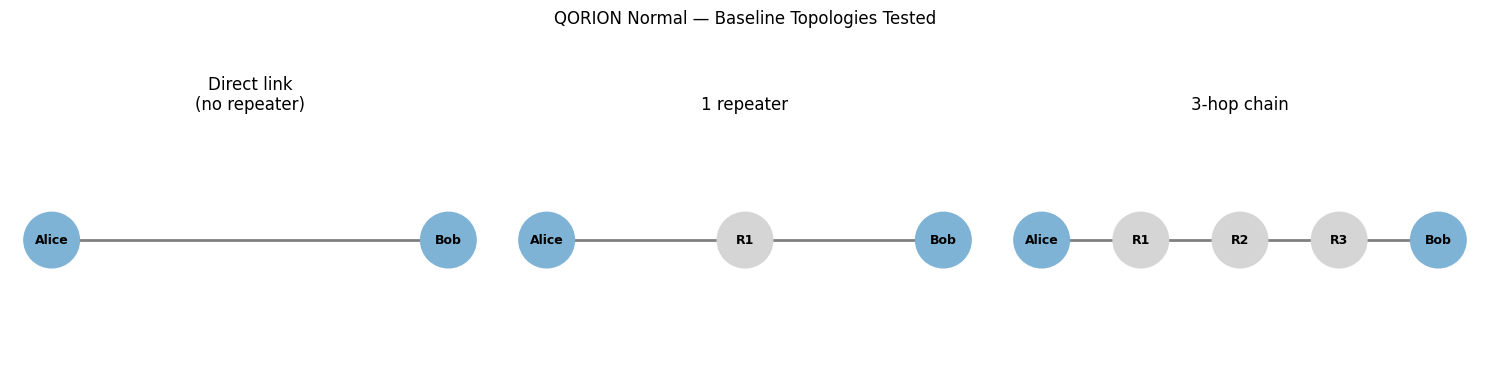

In [4]:
import networkx as nx
import matplotlib.pyplot as plt

def draw_topology(n_repeaters, ax, title):
    G = nx.Graph()
    G.add_node('Alice', pos=(0, 0))
    labels_order = ['Alice']
    for i in range(n_repeaters):
        name = f'R{i+1}'
        G.add_node(name, pos=(i + 1, 0))
        labels_order.append(name)
    G.add_node('Bob', pos=(n_repeaters + 1, 0))
    labels_order.append('Bob')

    for i in range(len(labels_order) - 1):
        G.add_edge(labels_order[i], labels_order[i + 1])

    pos = nx.get_node_attributes(G, 'pos')
    colors = ['#7fb3d5'] + ['#d5d5d5'] * n_repeaters + ['#7fb3d5']
    nx.draw(G, pos, ax=ax, with_labels=True, node_color=colors, node_size=1600,
            font_size=9, font_weight='bold', edge_color='gray', width=2)
    ax.set_title(title)

fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
draw_topology(0, axes[0], 'Direct link\n(no repeater)')
draw_topology(1, axes[1], '1 repeater')
draw_topology(3, axes[2], '3-hop chain')
plt.suptitle('QORION Normal — Baseline Topologies Tested', y=1.05)
plt.tight_layout()
plt.savefig('normal_topology.png', dpi=150, bbox_inches='tight')
plt.show()

## Parameter Sweep

Grid: `n_repeaters ∈ {0,1,2,3,4,5}` × `distance_km ∈ {5,10,20,30,40,50,60,80}`,
30 trials per configuration. Mean and standard deviation are recorded for
fidelity and wall-clock time, enabling error bars in the result plots below.

In [5]:
ATTENUATION = 0.0002
DISTANCES_KM = [5, 10, 20, 30, 40, 50, 60, 80]
REPEATER_COUNTS = [0, 1, 2, 3, 4, 5]
TRIALS = 30

normal_results = []

print(f"{'Distance':<10}{'Repeaters':<11}{'Success%':<11}{'Fidelity(±std)':<20}{'Time(±std)'}")
print("-" * 80)

for dist_km in DISTANCES_KM:
    for n_rep in REPEATER_COUNTS:
        runs = [run_honest_chain(dist_km * 1000, ATTENUATION, n_repeaters=n_rep) for _ in range(TRIALS)]
        successes = [r for r in runs if r.get('end_to_end_entangled')]
        success_rate = len(successes) / len(runs) * 100

        fids = [r['fidelity'] for r in successes]
        times = [r['wall_time'] for r in runs]
        attempts = [r.get('total_attempts', 0) for r in runs]

        avg_fid = statistics.mean(fids) if fids else 0.0
        std_fid = statistics.stdev(fids) if len(fids) > 1 else 0.0
        avg_time = statistics.mean(times)
        std_time = statistics.stdev(times) if len(times) > 1 else 0.0
        avg_attempts = statistics.mean(attempts)

        print(f"{dist_km}km{'':<6}{n_rep:<11}{success_rate:<11.0f}"
              f"{avg_fid:.3f}±{std_fid:.3f}{'':<8}{avg_time:.3f}±{std_time:.3f}")

        normal_results.append({
            'scenario': 'normal',
            'distance_km': dist_km,
            'n_hops': n_rep,
            'n_malicious': 0,
            'position': None,
            'attack_strategy': 'none',
            'n_paths': 1,
            'trials': TRIALS,
            'success_rate': success_rate,
            'confidentiality_broken_rate': None,
            'avg_fidelity': avg_fid,
            'std_fidelity': std_fid,
            'avg_time': avg_time,
            'std_time': std_time,
            'avg_attempts': avg_attempts,
        })

print(f"\nCompleted {len(normal_results)} configurations x {TRIALS} trials each")

Distance  Repeaters  Success%   Fidelity(±std)      Time(±std)
--------------------------------------------------------------------------------
5km      0          100        0.900±0.000        0.011±0.025
5km      1          100        0.802±0.000        0.009±0.001
5km      2          100        0.714±0.000        0.018±0.006
5km      3          100        0.637±0.000        0.026±0.019
5km      4          100        0.567±0.000        0.022±0.001
5km      5          100        0.505±0.000        0.026±0.003
10km      0          100        0.900±0.000        0.021±0.003
10km      1          100        0.802±0.000        0.012±0.001
10km      2          100        0.714±0.000        0.013±0.001
10km      3          100        0.637±0.000        0.018±0.003
10km      4          100        0.567±0.000        0.021±0.001
10km      5          100        0.505±0.000        0.027±0.004
20km      0          100        0.900±0.000        0.021±0.003
20km      1          100        0.802±0.000

## Result Visualization

Two figures: fidelity vs. distance (by repeater count), and success rate vs.
distance (by repeater count) — both with error bars from the standard
deviations recorded above.

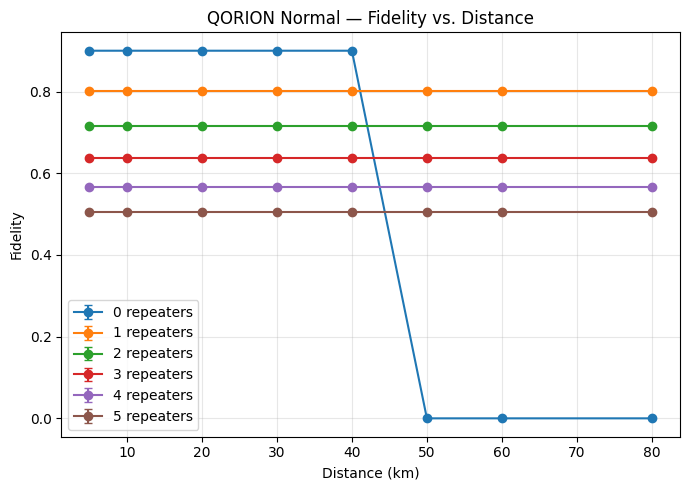

In [6]:
fig, ax = plt.subplots(figsize=(7, 5))
for n_rep in REPEATER_COUNTS:
    subset = [r for r in normal_results if r['n_hops'] == n_rep]
    subset.sort(key=lambda r: r['distance_km'])
    x = [r['distance_km'] for r in subset]
    y = [r['avg_fidelity'] for r in subset]
    yerr = [r['std_fidelity'] for r in subset]
    ax.errorbar(x, y, yerr=yerr, marker='o', capsize=3, label=f'{n_rep} repeaters')

ax.set_xlabel('Distance (km)')
ax.set_ylabel('Fidelity')
ax.set_title('QORION Normal — Fidelity vs. Distance')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('fig_normal_fidelity_vs_distance.png', dpi=300)
plt.show()

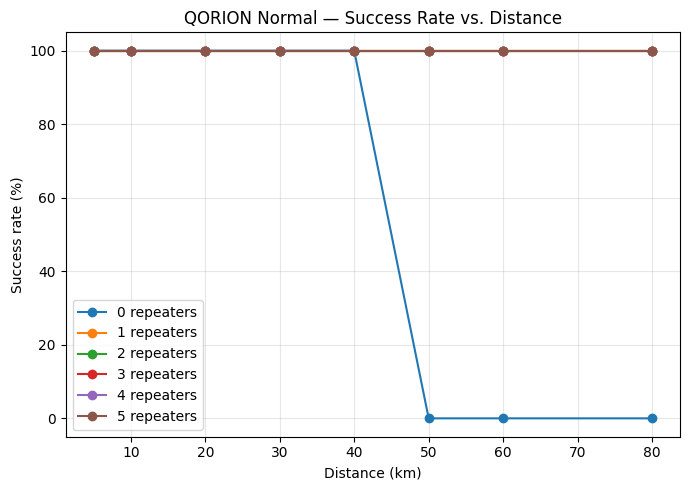

In [7]:
fig, ax = plt.subplots(figsize=(7, 5))
for n_rep in REPEATER_COUNTS:
    subset = [r for r in normal_results if r['n_hops'] == n_rep]
    subset.sort(key=lambda r: r['distance_km'])
    x = [r['distance_km'] for r in subset]
    y = [r['success_rate'] for r in subset]
    ax.plot(x, y, marker='o', label=f'{n_rep} repeaters')

ax.set_xlabel('Distance (km)')
ax.set_ylabel('Success rate (%)')
ax.set_title('QORION Normal — Success Rate vs. Distance')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('fig_normal_success_vs_distance.png', dpi=300)
plt.show()

## Export

Saves results to `normal_results.json` using the shared QORION schema, so the
Vulnerable, Proposed, and Final Analysis notebooks can load this file directly.

In [8]:
import json
import os

with open('normal_results.json', 'w') as f:
    json.dump(normal_results, f, indent=2)

if os.path.exists('normal_results.json'):
    size_kb = os.path.getsize('normal_results.json') / 1024
    print(f"✅ Saved normal_results.json ({size_kb:.1f} KB, {len(normal_results)} entries)")
else:
    print("❌ Save failed — file not found on disk")

from google.colab import files
files.download('normal_results.json')
print("Download triggered — confirm in your browser's download bar before closing this notebook")

✅ Saved normal_results.json (19.4 KB, 48 entries)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download triggered — confirm in your browser's download bar before closing this notebook
